# Kinetic Theory — Interactive Visualisations
## PSE Lab · SeoulTech · Chapters 1–4

This notebook produces interactive and animated figures that accompany the four-chapter Kinetic Theory lecture series.

| Figure | Chapter | Topic |
|--------|---------|-------|
| 1 | Ch 1 | Maxwell speed distribution — varying $T$ and $m$ |
| 2 | Ch 1 | Mean free path and transport coefficients vs. $T$ and $P$ |
| 3 | Ch 2 | Boltzmann H-function relaxation simulation |
| 4 | Ch 2 | Chapman-Enskog: sound dispersion and damping |
| 5 | Ch 3 | Brownian motion trajectories — Langevin simulation |
| 6 | Ch 3 | Fokker-Planck: probability distribution evolving in a potential |
| 7 | Ch 4 | Response function χ(ω): reactive and dissipative parts |
| 8 | Ch 4 | Fluctuation-dissipation theorem: noise spectra |


## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.gridspec import GridSpec
from scipy.stats import norm
from scipy.integrate import quad
import warnings
warnings.filterwarnings('ignore')

# ── Dark theme ────────────────────────────────────────────────────────────────
BG      = '#0d1117'
SURFACE = '#161b22'
BORDER  = '#30363d'
TEXT    = '#e6edf3'
MUTED   = '#8b949e'
TEAL    = '#2dd4bf'
BLUE    = '#388bfd'
GREEN   = '#3fb950'
RED     = '#f85149'
PURPLE  = '#bc8cff'
ORANGE  = '#f0883e'

def dark_ax(ax, grid=True):
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=MUTED, labelsize=10)
    ax.xaxis.label.set_color(TEXT); ax.yaxis.label.set_color(TEXT)
    ax.title.set_color(TEAL)
    for sp in ax.spines.values(): sp.set_edgecolor(BORDER)
    ax.axhline(0, color=BORDER, lw=0.8, zorder=0)
    if grid: ax.grid(True, color=BORDER, lw=0.5, alpha=0.5, zorder=0)

# Constants
kB = 1.380649e-23   # J/K
mN2 = 4.65e-26      # kg  (N₂)
mHe = 6.65e-27      # kg  (He)
mAr = 6.63e-26      # kg  (Ar)
print('Setup complete.')

Setup complete.


---
## Figure 1 — Maxwell Speed Distribution

$$f(v) = 4\pi n\left(\frac{m}{2\pi k_BT}\right)^{3/2} v^2 e^{-mv^2/2k_BT}$$

Sliders allow varying temperature $T$ and molecular mass $m$ (N₂, He, Ar).
The vertical lines show $v_p$ (most probable), $\bar{v}$ (mean), $v_{rms}$.


In [2]:
# ── Fig 1: Maxwell speed distribution ─────────────────────────────────────
from ipywidgets import interact, FloatSlider, Dropdown

def maxwell(v, T, m):
    """Maxwell speed distribution (normalised, per molecule)."""
    a = (m / (2 * kB * T))**0.5
    return 4 * np.pi * (a / np.sqrt(np.pi))**3 * v**2 * np.exp(-a**2 * v**2)

def plot_maxwell(T=300, molecule='N₂'):
    """Maxwell speed distribution: vary temperature and molecular mass."""
    masses = {'N₂': mN2, 'He': mHe, 'Ar': mAr}
    m = masses[molecule]

    v = np.linspace(0, 3000, 2000)
    f = maxwell(v, T, m)

    # Characteristic speeds
    vp   = np.sqrt(2 * kB * T / m)
    vbar = np.sqrt(8 * kB * T / (np.pi * m))
    vrms = np.sqrt(3 * kB * T / m)

    fig, ax = plt.subplots(figsize=(9, 5))
    fig.patch.set_facecolor(BG)
    dark_ax(ax)

    ax.plot(v, f, color=TEAL, lw=2.5, label='$f(v)$')
    ax.fill_between(v, f, alpha=0.12, color=TEAL)

    for val, y_loc, col, label in [(vp, 0.85, GREEN, '$v_p$'), (vbar, 0.75, ORANGE, '$\\bar{v}$'), (vrms, 0.65, RED, '$v_{rms}$')]:
        ax.axvline(val, color=col, lw=1.5, ls='--')
        ax.text(val+10, ax.get_ylim()[1]*y_loc if ax.get_ylim()[1]>0 else 0.001,
                f'{label} {val:.0f} m/s', color=col, fontsize=9, va='top')

    ax.set_xlabel('Speed $v$ (m/s)', fontsize=12)
    ax.set_ylabel('$f(v)$ (s/m)', fontsize=12)
    ax.set_title(f'Maxwell Speed Distribution — {molecule},  $T = {T}$ K', fontsize=12)
    ax.set_xlim(0, min(3000, vrms * 4))

    # Info box
    textstr = (f'$v_p = {vp:.0f}$ m/s\n$\\bar{{v}} = {vbar:.0f}$ m/s\n'
               f'$v_{{rms}} = {vrms:.0f}$ m/s\n$m = {m*1e27:.1f}$ yg')
    ax.text(0.97, 0.3, textstr, transform=ax.transAxes, fontsize=9,
            color=TEXT, va='top', ha='right',
            bbox=dict(facecolor=SURFACE, edgecolor=BORDER, alpha=0.9, boxstyle='round'))
    plt.tight_layout(); plt.show()

interact(plot_maxwell,
         T=FloatSlider(min=100, max=2000, step=50, value=300, description='T (K)'),
         molecule=Dropdown(options=['N₂','He','Ar'], value='N₂', description='Molecule'))

interactive(children=(FloatSlider(value=300.0, description='T (K)', max=2000.0, min=100.0, step=50.0), Dropdow…

<function __main__.plot_maxwell(T=300, molecule='N₂')>

---
## Figure 2 — Transport Coefficients vs. T and P

$$D \approx \tfrac{1}{3}\bar{v}\ell, \quad \eta = \rho D \propto \sqrt{T}, \quad \kappa = nc_v D$$

Key result: **viscosity is independent of pressure** (Maxwell, 1866).


In [3]:
# ── Fig 2: Transport coefficients ─────────────────────────────────────────
def plot_transport(molecule='N₂'):
    """Transport coefficients (D, η, κ) vs. temperature; viscosity vs. pressure."""
    masses = {'N₂': mN2, 'He': mHe, 'Ar': mAr}
    diams  = {'N₂': 3.7e-10, 'He': 2.6e-10, 'Ar': 3.4e-10}
    cvs    = {'N₂': 5/2*kB, 'He': 3/2*kB, 'Ar': 3/2*kB}  # per molecule
    m  = masses[molecule]
    d  = diams[molecule]
    cv = cvs[molecule]
    sigma = np.pi * d**2

    T_arr = np.linspace(100, 1500, 300)
    P_ref = 1e5   # Pa (1 atm)

    n  = P_ref / (kB * T_arr)
    vbar = np.sqrt(8 * kB * T_arr / (np.pi * m))
    ell = 1 / (n * sigma)
    rho = n * m

    D_arr   = vbar * ell / 3
    eta_arr = rho * D_arr
    # κ = n·cv·D  with cv = 5/2·kB for diatomic (N₂/Ar uses 3/2·kB)
    kappa_arr = n * cv * D_arr

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
    fig.patch.set_facecolor(BG)

    data = [
        (D_arr * 1e4, '$D$ (cm²/s)', TEAL, '$D \\propto T^{3/2}/P$'),
        (eta_arr * 1e6, '$\\eta$ (μPa·s)', ORANGE, '$\\eta \\propto \\sqrt{T}$ (P-independent!)'),
        (kappa_arr * 1e3, '$\\kappa$ (mW/m·K)', RED, '$\\kappa \\propto \\sqrt{T}$  (kinetic estimate)'),
    ]

    for ax, (y, ylabel, col, note) in zip(axes, data):
        dark_ax(ax)
        ax.plot(T_arr, y, color=col, lw=2.2)
        ax.set_xlabel('Temperature $T$ (K)', fontsize=11)
        ax.set_ylabel(ylabel, fontsize=11)
        ax.set_title(note, fontsize=10)
        ax.set_xlim(100, 1500)

    fig.suptitle(f'Transport Coefficients — {molecule} at $P = 10^5$ Pa', color=TEXT, fontsize=13)
    plt.tight_layout(); plt.show()

    # Pressure independence of viscosity
    fig2, ax = plt.subplots(figsize=(7, 4))
    fig2.patch.set_facecolor(BG); dark_ax(ax)
    P_arr = np.logspace(3, 7, 200)
    T0 = 300
    n0 = P_arr / (kB * T0)
    vbar0 = np.sqrt(8*kB*T0/(np.pi*m))
    ell0 = 1/(n0*sigma)
    eta0 = n0*m*vbar0*ell0/3 * 1e6
    ax.semilogx(P_arr/1e5, eta0, color=ORANGE, lw=2.5)
    ax.set_xlabel('Pressure $P$ (atm)', fontsize=12)
    ax.set_ylabel('$\\eta$ (μPa·s)', fontsize=12)
    ax.set_title(f'Viscosity vs. Pressure — {molecule},  $T = {T0}$ K\n(independent of P!)', fontsize=11)
    ax.set_xlim(P_arr[0]/1e5, P_arr[-1]/1e5)
    plt.tight_layout(); plt.show()

from ipywidgets import interact, Dropdown
interact(plot_transport, molecule=Dropdown(options=['N₂','He','Ar'], value='N₂', description='Molecule'))

interactive(children=(Dropdown(description='Molecule', options=('N₂', 'He', 'Ar'), value='N₂'), Output()), _do…

<function __main__.plot_transport(molecule='N₂')>

---
## Figure 3 — Boltzmann H-Function: Relaxation to Equilibrium

Simulate a 1D velocity distribution relaxing toward Maxwell-Boltzmann via random-collision kinetics.
$H(t) = \int f\ln f\,dp$ decreases monotonically — the H-theorem in action.


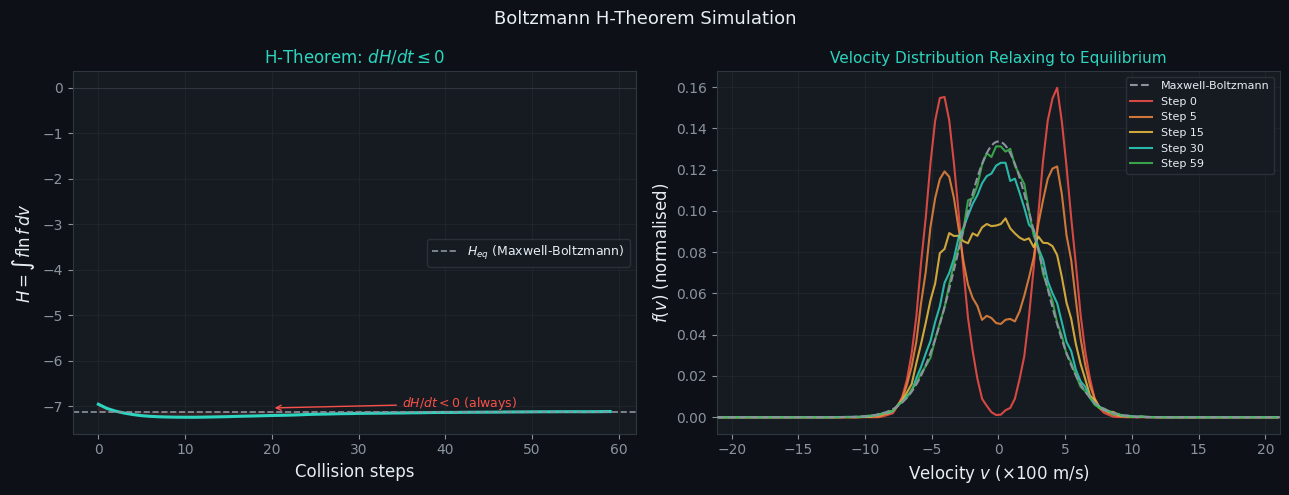

H decreased from -6.954 to -7.114 (equilibrium: -7.118)


In [4]:
# ── Fig 3: H-function relaxation ─────────────────────────────────────────
np.random.seed(42)
T = 300; m = mN2
N = 50000  # particles

# Start with a bimodal distribution (two beams)
v_half = int(N/2)
vbeam = np.sqrt(2*kB*T/m)
velocities = np.concatenate([
    np.random.normal(+vbeam, vbeam*0.3, v_half),
    np.random.normal(-vbeam, vbeam*0.3, N - v_half)
])

def compute_H(v_arr, nbins=150):
    vmax = 5 * np.sqrt(2*kB*T/m)
    hist, edges = np.histogram(v_arr, bins=nbins, range=(-vmax, vmax), density=True)
    hist = np.where(hist > 1e-12, hist, 1e-12)
    dv = edges[1] - edges[0]
    return np.sum(hist * np.log(hist) * dv)

def relax_step(v_arr, frac=0.05):
    """Random collision relaxation: replace frac of particles with Maxwell draws."""
    n_replace = int(len(v_arr) * frac)
    idx = np.random.choice(len(v_arr), n_replace, replace=False)
    vsig = np.sqrt(kB*T/m)
    v_arr[idx] = np.random.normal(0, vsig, n_replace)
    return v_arr

# Run simulation
n_steps = 60
H_vals = []
v_snap = velocities.copy()
snapshots = []

for step in range(n_steps):
    H_vals.append(compute_H(v_snap))
    if step in [0, 5, 15, 30, 59]:
        snapshots.append((step, v_snap.copy()))
    v_snap = relax_step(v_snap, frac=0.08)

H_eq = compute_H(np.random.normal(0, np.sqrt(kB*T/m), N*5))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.patch.set_facecolor(BG)
ax1, ax2 = axes
dark_ax(ax1); dark_ax(ax2)

# Left: H(t)
steps = np.arange(n_steps)
ax1.plot(steps, H_vals, color=TEAL, lw=2.2)
ax1.axhline(H_eq, color=MUTED, lw=1.2, ls='--', label='$H_{eq}$ (Maxwell-Boltzmann)')
ax1.fill_between(steps, H_vals, H_eq, alpha=0.1, color=RED)
ax1.set_xlabel('Collision steps', fontsize=12)
ax1.set_ylabel('$H = \int f \ln f\, dv$', fontsize=12)
ax1.set_title('H-Theorem: $dH/dt \leq 0$', fontsize=12)
ax1.legend(fontsize=9, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER)
ax1.annotate('$dH/dt < 0$ (always)', xy=(20, (H_vals[0]+H_eq)/2),
             xytext=(35, (H_vals[0]+H_eq)/2 + 0.1*(H_vals[0]-H_eq)),
             fontsize=9, color=RED, arrowprops=dict(arrowstyle='->', color=RED))

# Right: velocity distribution snapshots
vmax = 5*np.sqrt(2*kB*T/m)
v_plot = np.linspace(-vmax, vmax, 300)
f_eq = (np.exp(-mN2*v_plot**2/(2*kB*T)) / np.sqrt(2*np.pi*kB*T/mN2))
ax2.plot(v_plot/1e2, f_eq/1e-2, color=MUTED, lw=1.5, ls='--', label='Maxwell-Boltzmann', zorder=10)

colors_snap = [RED, ORANGE, '#f0c040', TEAL, GREEN]
for (step, v_s), col in zip(snapshots, colors_snap):
    hist, edges = np.histogram(v_s, bins=120, range=(-vmax, vmax), density=True)
    v_mid = (edges[:-1]+edges[1:])/2
    ax2.plot(v_mid/1e2, hist/1e-2, color=col, lw=1.5, alpha=0.85, label=f'Step {step}')

ax2.set_xlabel('Velocity $v$ (×100 m/s)', fontsize=12)
ax2.set_ylabel('$f(v)$ (normalised)', fontsize=12)
ax2.set_title('Velocity Distribution Relaxing to Equilibrium', fontsize=11)
ax2.legend(fontsize=8, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER)
ax2.set_xlim(-vmax/1e2, vmax/1e2)

fig.suptitle('Boltzmann H-Theorem Simulation', color=TEXT, fontsize=13)
plt.tight_layout(); plt.show()
print(f'H decreased from {H_vals[0]:.3f} to {H_vals[-1]:.3f} (equilibrium: {H_eq:.3f})')

---
## Figure 4 — Sound Dispersion and Damping (Ch 2)

Sound in a viscous fluid: $\omega = v_s k - \frac{i}{2}\Gamma k^2 + \ldots$

Damping coefficient $\Gamma = \frac{\eta}{\rho}\left(\frac{4}{3}+\frac{\kappa}{\eta c_v/m}\right)$.


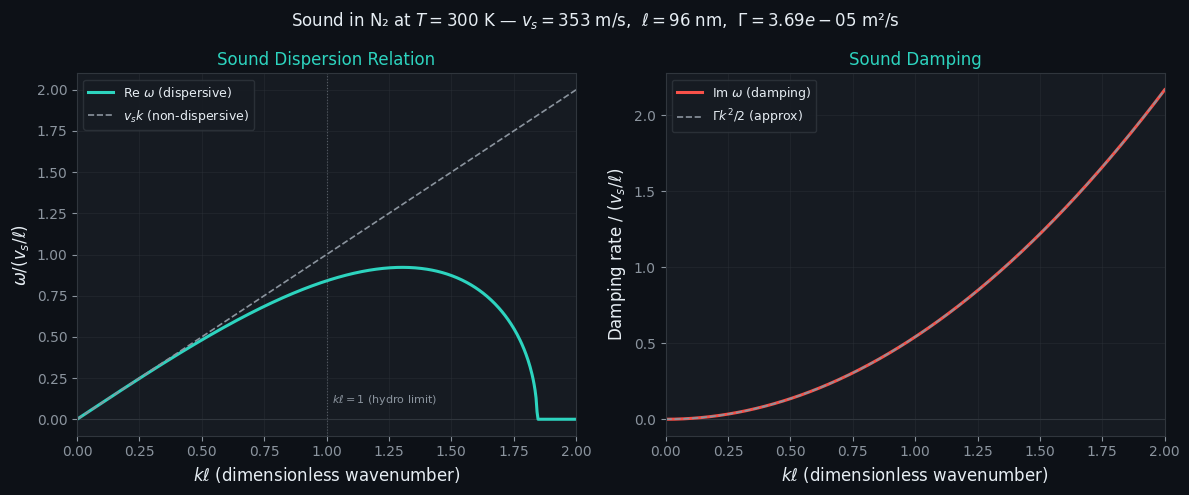

In [5]:
# ── Fig 4: Sound dispersion ────────────────────────────────────────────────
# Parameters: N₂ at 300K, 1atm
T = 300; P = 1e5
m = mN2; cv_mol = 5/2*kB  # N2 diatomic
n = P/(kB*T); rho = n*m
vbar = np.sqrt(8*kB*T/(np.pi*m))
sigma = np.pi*(3.7e-10)**2
ell = 1/(n*sigma)
tau = ell/vbar

eta   = n*kB*T*tau
kappa = 5/2*(n*kB**2*T*tau/m)
vs    = np.sqrt(7/5 * kB*T/m)   # adiabatic sound speed (gamma=7/5 for N2)
cp_mol = 7/2*kB                  # heat capacity at constant pressure (diatomic: cp=cv+kB)
Gamma = eta/rho * (4/3 + kappa*m/(eta*cp_mol))   # correct: cp not cv in thermal damping

k_arr = np.linspace(0, 2/ell, 500)
k_arr[0] = 1e-10  # avoid zero

# Exact dispersion from linearised Navier-Stokes
omega_exact = np.sqrt(np.maximum(vs**2*k_arr**2 - (Gamma*k_arr**2/2)**2, 0))
gamma_exact = Gamma * k_arr**2 / 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)
dark_ax(ax1); dark_ax(ax2)

k_norm = k_arr * ell
ax1.plot(k_norm, omega_exact/(vs/ell), color=TEAL, lw=2.2, label='Re $\\omega$ (dispersive)')
ax1.plot(k_norm, vs*k_arr/(vs/ell), color=MUTED, lw=1.2, ls='--', label='$v_s k$ (non-dispersive)')
ax1.set_xlabel('$k\\ell$ (dimensionless wavenumber)', fontsize=12)
ax1.set_ylabel('$\\omega / (v_s/\\ell)$', fontsize=12)
ax1.set_title('Sound Dispersion Relation', fontsize=12)
ax1.set_xlim(0, 2); ax1.legend(fontsize=9, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER)
ax1.axvline(1, color=MUTED, lw=0.8, ls=':', alpha=0.5)
ax1.text(1.02, 0.1, '$k\\ell=1$ (hydro limit)', color=MUTED, fontsize=8)

ax2.plot(k_norm, gamma_exact/(vs/ell), color=RED, lw=2.2, label='Im $\\omega$ (damping)')
ax2.plot(k_norm, Gamma*k_arr**2/2/(vs/ell), color=MUTED, lw=1.2, ls='--', label='$\\Gamma k^2/2$ (approx)')
ax2.set_xlabel('$k\\ell$ (dimensionless wavenumber)', fontsize=12)
ax2.set_ylabel('Damping rate / $(v_s/\\ell)$', fontsize=12)
ax2.set_title('Sound Damping', fontsize=12)
ax2.set_xlim(0, 2); ax2.legend(fontsize=9, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER)

fig.suptitle(f'Sound in N₂ at $T={T}$ K — $v_s={vs:.0f}$ m/s,  $\\ell={ell*1e9:.0f}$ nm,  $\\Gamma={Gamma:.2e}$ m²/s',
             color=TEXT, fontsize=12)
plt.tight_layout(); plt.show()

---
## Figure 5 — Brownian Motion: Langevin Simulation (Ch 3)

$$m\ddot{x} = -\gamma\dot{x} + \eta(t), \quad \langle\eta(t)\eta(t')\rangle = 2\gamma k_BT\,\delta(t-t')$$

Show ballistic ($t\ll\tau$) to diffusive ($t\gg\tau$) crossover.


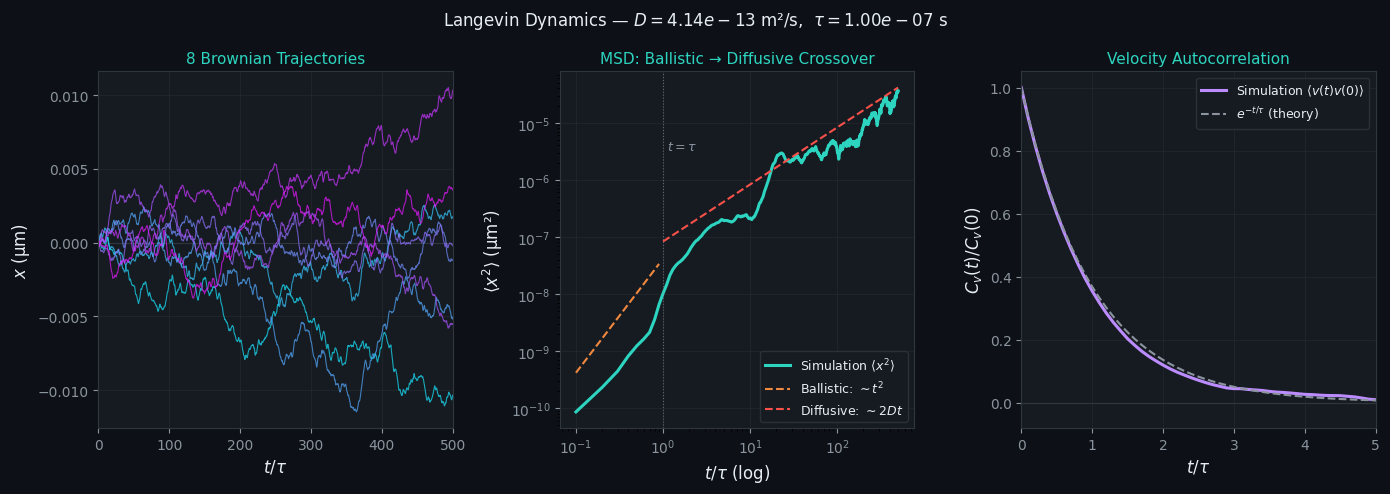

In [6]:
# ── Fig 5: Langevin simulation ─────────────────────────────────────────────
np.random.seed(7)

# Parameters: μm-scale bead in water
kT   = kB * 300        # J
m    = 1e-15           # kg  (1 μm bead)
gamma = 1e-8           # kg/s (Stokes friction in water, r=0.5μm)
D    = kT / gamma      # m²/s
tau  = m / gamma       # velocity relaxation time

dt   = tau * 0.1
N_t  = 5000
N_traj = 8

t_arr = np.arange(N_t) * dt

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)
ax1, ax2, ax3 = axes
dark_ax(ax1); dark_ax(ax2); dark_ax(ax3)

msd_all = np.zeros(N_t)
colors_t = plt.cm.cool(np.linspace(0.1, 0.9, N_traj))

for ti in range(N_traj):
    x = np.zeros(N_t); v = 0.0
    for i in range(1, N_t):
        noise = np.sqrt(2 * gamma * kT * dt) / m * np.random.randn()
        v = v * (1 - gamma*dt/m) + noise
        x[i] = x[i-1] + v * dt
    ax1.plot(t_arr/tau, x*1e6, color=colors_t[ti], lw=0.8, alpha=0.7)
    msd_all += x**2

ax1.set_xlabel('$t / \\tau$', fontsize=12)
ax1.set_ylabel('$x$ (μm)', fontsize=12)
ax1.set_title(f'{N_traj} Brownian Trajectories', fontsize=11)
ax1.set_xlim(0, N_t*dt/tau)

# MSD
msd_avg = msd_all / N_traj
ax2.loglog(t_arr[1:]/tau, msd_avg[1:]*1e12, color=TEAL, lw=2.2, label='Simulation $\\langle x^2\\rangle$')
t_bal = t_arr[1:]
ax2.loglog(t_bal[t_bal<tau]/tau, (kT/m*t_bal[t_bal<tau]**2)*1e12, color=ORANGE, lw=1.5, ls='--', label='Ballistic: $\\sim t^2$')
ax2.loglog(t_bal[t_bal>tau]/tau, (2*D*t_bal[t_bal>tau])*1e12, color=RED, lw=1.5, ls='--', label='Diffusive: $\\sim 2Dt$')
ax2.set_xlabel('$t / \\tau$ (log)', fontsize=12)
ax2.set_ylabel('$\\langle x^2\\rangle$ (μm²)', fontsize=12)
ax2.set_title('MSD: Ballistic → Diffusive Crossover', fontsize=11)
ax2.legend(fontsize=9, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER)
ax2.axvline(1, color=MUTED, lw=0.8, ls=':', alpha=0.6)
ax2.text(1.1, msd_avg[int(0.1*N_t)]*1e12, '$t=\\tau$', color=MUTED, fontsize=9)

# Velocity autocorrelation
v_arr = np.zeros((N_traj, N_t))
for ti in range(N_traj):
    v = 0.0
    for i in range(N_t):
        noise = np.sqrt(2*gamma*kT*dt)/m * np.random.randn()
        v = v*(1-gamma*dt/m) + noise
        v_arr[ti, i] = v
max_lag = 200
C = np.array([np.mean(v_arr[:, :N_t-lag] * v_arr[:, lag:]) for lag in range(max_lag)])
C /= C[0]
t_lag = np.arange(max_lag) * dt
ax3.plot(t_lag/tau, C, color=PURPLE, lw=2.2, label='Simulation $\\langle v(t)v(0)\\rangle$')
ax3.plot(t_lag/tau, np.exp(-t_lag/tau), color=MUTED, lw=1.5, ls='--', label='$e^{-t/\\tau}$ (theory)')
ax3.axhline(0, color=BORDER, lw=0.8)
ax3.set_xlabel('$t / \\tau$', fontsize=12)
ax3.set_ylabel('$C_v(t) / C_v(0)$', fontsize=12)
ax3.set_title('Velocity Autocorrelation', fontsize=11)
ax3.legend(fontsize=9, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER)
ax3.set_xlim(0, 5)

fig.suptitle(f'Langevin Dynamics — $D = {D:.2e}$ m²/s,  $\\tau = {tau:.2e}$ s', color=TEXT, fontsize=12)
plt.tight_layout(); plt.show()

---
## Figure 6 — Fokker-Planck: Probability Distribution in a Potential (Ch 3)

Overdamped particle in a double-well $U(x) = x^4 - 2x^2$.
The probability distribution $P(x,t)$ evolves toward $P_{st} \propto e^{-\beta U}$.


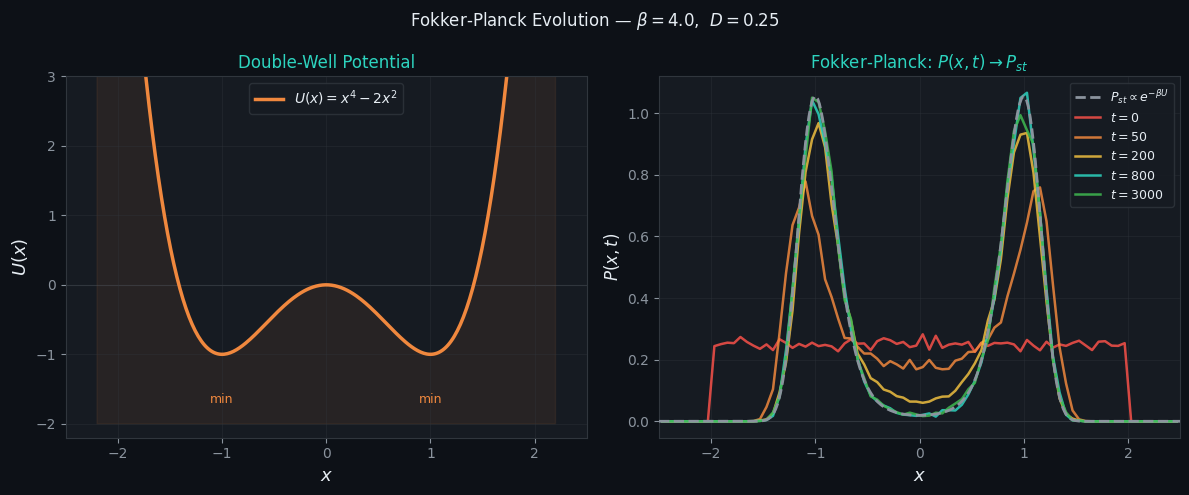

In [7]:
# ── Fig 6: Fokker-Planck in double-well ───────────────────────────────────
np.random.seed(42)

# Parameters (dimensionless units)
beta = 4.0       # inverse temperature (higher = sharper wells)
D_fp = 1/beta    # diffusion coefficient
gamma_fp = 1.0
N_p = 20000      # particles
dt_fp = 0.002

def U(x):  return x**4 - 2*x**2
def dU(x): return 4*x**3 - 4*x

# Run overdamped Langevin: γẋ = -dU/dx + η
x_fp = np.random.uniform(-2, 2, N_p)
x_history = [x_fp.copy()]
t_steps = [0, 50, 200, 800, 3000]
t = 0; step = 0
all_steps = max(t_steps)
next_save = 1

while step < all_steps:
    force = -dU(x_fp) / gamma_fp
    noise = np.sqrt(2*D_fp*dt_fp) * np.random.randn(N_p)
    x_fp = x_fp + force*dt_fp + noise
    x_fp = np.clip(x_fp, -3, 3)
    step += 1
    if step in t_steps:
        x_history.append(x_fp.copy())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)
ax1, ax2 = axes
dark_ax(ax1); dark_ax(ax2)

# Left: potential
x_pot = np.linspace(-2.2, 2.2, 300)
ax1.plot(x_pot, U(x_pot), color=ORANGE, lw=2.5, label='$U(x) = x^4 - 2x^2$')
ax1.fill_between(x_pot, U(x_pot), -2, alpha=0.08, color=ORANGE)
ax1.set_xlabel('$x$', fontsize=13); ax1.set_ylabel('$U(x)$', fontsize=13)
ax1.set_title('Double-Well Potential', fontsize=12)
ax1.set_xlim(-2.5, 2.5); ax1.set_ylim(-2.2, 3)
ax1.legend(fontsize=10, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER)
ax1.text(-1, -1.7, 'min', color=ORANGE, fontsize=9, ha='center')
ax1.text( 1, -1.7, 'min', color=ORANGE, fontsize=9, ha='center')

# Right: P(x,t) snapshots
x_range = np.linspace(-2.5, 2.5, 300)
P_eq = np.exp(-beta * U(x_range))
P_eq /= np.trapz(P_eq, x_range)
ax2.plot(x_range, P_eq, color=MUTED, lw=2.0, ls='--', label='$P_{st} \\propto e^{-\\beta U}$', zorder=10)

snap_colors = [RED, ORANGE, '#f0c040', TEAL, GREEN]
times_label = [0] + t_steps[1:]
for xi, col, tlabel in zip(x_history, snap_colors, times_label):
    hist, edges = np.histogram(xi, bins=80, range=(-2.5,2.5), density=True)
    vm = (edges[:-1]+edges[1:])/2
    ax2.plot(vm, hist, color=col, lw=1.8, alpha=0.85, label=f'$t={tlabel}$')

ax2.set_xlabel('$x$', fontsize=13)
ax2.set_ylabel('$P(x, t)$', fontsize=12)
ax2.set_title('Fokker-Planck: $P(x,t) \\to P_{st}$', fontsize=12)
ax2.legend(fontsize=9, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER)
ax2.set_xlim(-2.5, 2.5)

fig.suptitle(f'Fokker-Planck Evolution — $\\beta={beta}$,  $D={D_fp}$', color=TEXT, fontsize=12)
plt.tight_layout(); plt.show()

---
## Figure 7 — Response Function χ(ω): Reactive and Dissipative Parts (Ch 4)

$$\chi(\omega) = \frac{1}{\omega_0^2 - \omega^2 - i\gamma\omega}$$

Interactive sliders for $\omega_0$ and $\gamma$.


In [8]:
# ── Fig 7: Response function ──────────────────────────────────────────────
from ipywidgets import interact, FloatSlider

def plot_response(omega0=1.0, gamma=0.3):
    """Damped oscillator response function χ'(ω) and χ''(ω)."""
    omega = np.linspace(-5, 5, 2000)
    D2 = (omega0**2 - omega**2)**2 + (gamma*omega)**2
    chi_re = (omega0**2 - omega**2) / D2
    chi_im = gamma*omega / D2

    y_lim = min(5, 1.5/gamma)

    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={'hspace':0.12})
    fig.patch.set_facecolor(BG)
    for ax in axes: dark_ax(ax)
    ax1, ax2 = axes

    ax1.plot(omega, chi_re, color=TEAL, lw=2.2)
    ax1.scatter([0], [1/omega0**2], s=80, color=GREEN, zorder=5)
    ax1.annotate(f"$\\chi'(0)=1/ \\omega_0^2={1/omega0**2:.2f}$",
                 xy=(0, 1/omega0**2), xytext=(0.3, y_lim*0.8),
                 fontsize=9, color=GREEN, arrowprops=dict(arrowstyle='->', color=GREEN))
    ax1.axvline( omega0, color=MUTED, lw=0.8, ls=':', alpha=0.6)
    ax1.axvline(-omega0, color=MUTED, lw=0.8, ls=':', alpha=0.6)
    ax1.set_ylabel("$\\chi'(\\omega)$ — Reactive", fontsize=12)
    ax1.set_ylim(-y_lim, y_lim)
    ax1.set_title(f"Damped Oscillator Response: $\\omega_0={omega0}$, $\\gamma={gamma}$", fontsize=12)

    ax2.plot(omega, chi_im, color=ORANGE, lw=2.2)
    ax2.fill_between(omega, chi_im, 0, where=(omega>0), alpha=0.12, color=ORANGE)
    ax2.fill_between(omega, chi_im, 0, where=(omega<0), alpha=0.12, color=RED)
    peak_val = 1/(gamma*omega0)
    ax2.annotate(f'$\\chi''(\\omega_0)=1/\\gamma\\omega_0={peak_val:.2f}$',
                 xy=(omega0, peak_val*0.98), xytext=(omega0+0.5, y_lim*0.7),
                 fontsize=9, color=ORANGE, arrowprops=dict(arrowstyle='->', color=ORANGE))
    ax2.axvline( omega0, color=MUTED, lw=0.8, ls=':', alpha=0.6)
    ax2.axvline(-omega0, color=MUTED, lw=0.8, ls=':', alpha=0.6)
    ax2.set_xlabel('$\\omega$', fontsize=13)
    ax2.set_ylabel("$\\chi''(\\omega)$ — Dissipative", fontsize=12)
    ax2.set_ylim(-y_lim, y_lim)
    ax2.set_xlim(-5, 5)
    plt.tight_layout(); plt.show()

interact(plot_response,
         omega0=FloatSlider(min=0.3, max=3.0, step=0.1, value=1.0, description='ω₀'),
         gamma =FloatSlider(min=0.05, max=2.0, step=0.05, value=0.3, description='γ'))

interactive(children=(FloatSlider(value=1.0, description='ω₀', max=3.0, min=0.3), FloatSlider(value=0.3, descr…

<function __main__.plot_response(omega0=1.0, gamma=0.3)>

---
## Figure 8 — Fluctuation-Dissipation Theorem: Noise Spectra (Ch 4)

$$S(\omega) = -2[n_B(\omega)+1]\chi''(\omega), \quad n_B(\omega) = \frac{1}{e^{\hbar\omega/k_BT}-1}$$

The "+1" is quantum (zero-point) noise; $n_B$ is thermal noise.
Johnson-Nyquist: $S_V(\omega) = 4k_BTR$ in the classical limit.


In [9]:
# ── Fig 8: Fluctuation-Dissipation Theorem ────────────────────────────────
from ipywidgets import interact, FloatLogSlider, FloatSlider

hbar = 1.0546e-34

def nB(omega, T):
    x = hbar*np.abs(omega)/(kB*T)
    return np.where(x < 1e-6, kB*T/(hbar*np.abs(omega)+1e-30),
                    1/(np.exp(np.clip(x,0,500))-1+1e-300))

def plot_fdt(T=300, gamma_fdt=0.3, omega0_fdt=1e12):
    """Fluctuation-Dissipation Theorem: noise spectrum S(ω) at various temperatures."""
    omega = np.linspace(-4e12, 4e12, 3000)
    D2 = (omega0_fdt**2 - omega**2)**2 + (gamma_fdt*omega0_fdt*omega)**2
    chi_im = gamma_fdt*omega0_fdt*omega / D2

    # FDT: S(ω) = 2[n_B(ω)+1] χ''(ω)  (positive-definite noise spectrum)
    # Note: χ''(ω) > 0 for ω > 0 with our sign convention → S ≥ 0
    S_quantum   = 2*(nB(omega, T)+1)*chi_im
    # Classical limit kBT >> ℏω: nB+1 ≈ kBT/ℏω → S_cl = 2kBT/ω * χ''(ω)
    safe_omega  = np.where(np.abs(omega) > 1e6, np.abs(omega), 1e6)
    S_classical = np.where(np.abs(omega) > 1e6, 2*kB*T/safe_omega*np.abs(chi_im)*np.sign(omega), 0)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.patch.set_facecolor(BG)
    dark_ax(axes[0]); dark_ax(axes[1])

    # Left: S(omega)
    axes[0].plot(omega/1e12, S_quantum, color=TEAL, lw=2.2, label='Quantum FDT')
    axes[0].plot(omega/1e12, S_classical, color=ORANGE, lw=1.5, ls='--', label='Classical ($k_BT\\gg\\hbar\\omega$)')
    axes[0].fill_between(omega/1e12, S_quantum, 0, where=(omega>0), alpha=0.15, color=TEAL)
    axes[0].set_xlabel('$\\omega$ (THz)', fontsize=12)
    axes[0].set_ylabel('$S(\\omega)$ (noise spectrum)', fontsize=11)
    axes[0].set_title(f'FDT: $S(\\omega) = 2[n_B(\\omega)+1]\\chi\'\'(\\omega)$\n$T={T}$ K', fontsize=11)
    axes[0].legend(fontsize=9, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER)

    # Right: temperature dependence
    T_arr = [50, 150, 300, 1000]
    T_cols = [BLUE, TEAL, ORANGE, RED]
    for T_i, col in zip(T_arr, T_cols):
        S_i = 2*(nB(omega, T_i)+1)*chi_im
        axes[1].plot(omega/1e12, S_i, color=col, lw=1.8, label=f'$T={T_i}$ K')
    axes[1].set_xlabel('$\\omega$ (THz)', fontsize=12)
    axes[1].set_ylabel('$S(\\omega)$', fontsize=11)
    axes[1].set_title('FDT: Temperature Dependence\n(quantum $\\to$ classical crossover)', fontsize=11)
    axes[1].legend(fontsize=9, facecolor=SURFACE, labelcolor=TEXT, edgecolor=BORDER)

    # Classical limit annotation
    x_cross = kB*T/(hbar) / 1e12
    axes[1].axvline(x_cross, color=MUTED, lw=0.8, ls=':', alpha=0.7)
    if x_cross < 3.5:
        axes[1].text(x_cross+0.1, axes[1].get_ylim()[1]*0.9,
                     f'$k_BT/\\hbar$', color=MUTED, fontsize=8)

    fig.suptitle('Fluctuation-Dissipation Theorem — Johnson-Nyquist Noise Spectrum', color=TEXT, fontsize=12)
    plt.tight_layout(); plt.show()

interact(plot_fdt,
         T=FloatSlider(min=10, max=2000, step=10, value=300, description='T (K)'),
         gamma_fdt=FloatSlider(min=0.05, max=1.0, step=0.05, value=0.3, description='γ/ω₀'),
         omega0_fdt=FloatLogSlider(min=10, max=13, step=0.5, value=12, description='ω₀ (log)'))

interactive(children=(FloatSlider(value=300.0, description='T (K)', max=2000.0, min=10.0, step=10.0), FloatSli…

<function __main__.plot_fdt(T=300, gamma_fdt=0.3, omega0_fdt=1000000000000.0)>

---
## Summary: All 8 Interactive Figures

| # | Chapter | Tool | Key Physics |
|---|---------|------|------------|
| 1 | Ch 1 | `interact` | Maxwell distribution: $T$ and $m$ dependence of $v_p, \bar{v}, v_{rms}$ |
| 2 | Ch 1 | `interact` | Transport $\propto\sqrt{T}$; viscosity pressure-independent |
| 3 | Ch 2 | Simulation | H-theorem: $dH/dt\le 0$; bimodal → Maxwell-Boltzmann |
| 4 | Ch 2 | Plot | Sound: $\omega = v_s k - i\Gamma k^2/2$; damping at $k\ell\sim 1$ |
| 5 | Ch 3 | Simulation | Langevin: ballistic → diffusive crossover; $\langle v(t)v(0)\rangle\propto e^{-t/\tau}$ |
| 6 | Ch 3 | Simulation | Fokker-Planck: $P(x,t)\to e^{-\beta U}$ in a double-well |
| 7 | Ch 4 | `interact` | $\chi'(\omega)$ reactive, $\chi''(\omega)$ dissipative; pole locations |
| 8 | Ch 4 | `interact` | FDT: quantum vs classical noise; Johnson-Nyquist |
